# Cyclistic Bike-Share Analysis: Charts

This notebook draws the charts for Q1 to Q4 in `docs/analysis_finding.md`. The maps for Q5 are made in Tableau Public.

- Input: summary tables in `data/divvy.duckdb`, built by `sql/05_analysis.sql`
- Output: PNG files in `figures/`
- The notebook only reads the summary tables. All aggregation is done in SQL.

In [1]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Read-only connection, so the file is never changed from here
con = duckdb.connect('../data/divvy.duckdb', read_only=True)

# Fixed colors for the two groups in every chart
COLORS = {'casual': '#eb6834', 'member': '#2a78d6'}
FIG_DIR = Path('../figures')

plt.rcParams.update({
    'figure.dpi': 100,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

def save_fig(fig, name):
    """Save a chart to figures/ with the same resolution and margins."""
    fig.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

# Check the connection: list the summary tables
con.sql("""
    SELECT table_name
    FROM information_schema.tables
    WHERE table_name LIKE 'q%'
    ORDER BY table_name
""").df()

,table_name
0,q1_ride_counts
1,q2_duration_buckets
2,q2_duration_stats
3,q3_rides_by_hour
4,q4_bike_type
5,q5_station_summary
6,q5_top_stations


## Q1 How many rides does each group take?

Metric: ride count and share by rider type (all 5,871,390 cleaned rides).

,member_casual,n_rides,share_pct
0,casual,2068692,35.23
1,member,3802698,64.77


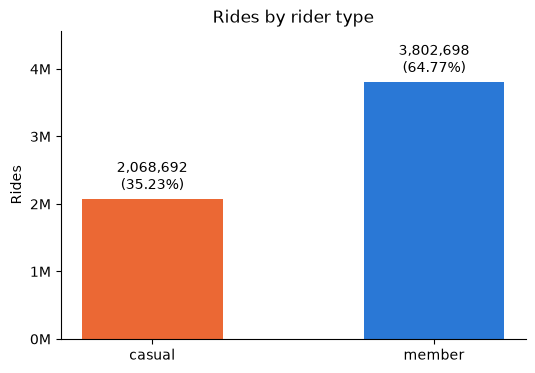

In [2]:
q1 = con.sql("""
    SELECT member_casual, n_rides, share_pct
    FROM q1_ride_counts
    ORDER BY member_casual
""").df()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(q1['member_casual'], q1['n_rides'],
              color=[COLORS[g] for g in q1['member_casual']], width=0.5)

# Label each bar with the ride count and the share of all rides
ax.bar_label(bars,
             labels=[f'{n:,}\n({s:.2f}%)' for n, s in zip(q1['n_rides'], q1['share_pct'])],
             padding=4)

ax.set_title('Rides by rider type')
ax.set_ylabel('Rides')
ax.yaxis.set_major_formatter(lambda y, _: f'{y / 1e6:.0f}M')
ax.set_ylim(0, q1['n_rides'].max() * 1.2)

save_fig(fig, 'q1_ride_counts')
q1

## Q2 How long do they ride?

Metric: median ride duration and interquartile range (25th to 75th percentile), plus the share of rides in six duration ranges.

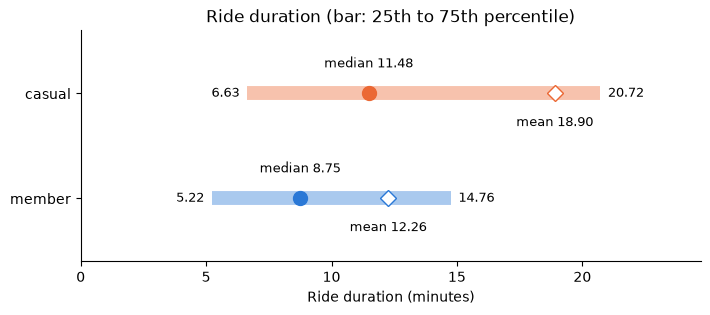

In [3]:
q2_stats = con.sql("""
    SELECT *
    FROM q2_duration_stats
    ORDER BY member_casual
""").df()
fig, ax = plt.subplots(figsize=(8, 3))

for y, row in enumerate(q2_stats.itertuples()):
    color = COLORS[row.member_casual]
    # Bar from the 25th to the 75th percentile, filled dot at the median, hollow diamond at the mean
    ax.hlines(y, row.p25_minutes, row.p75_minutes, color=color, linewidth=10, alpha=0.4)
    ax.plot(row.median_minutes, y, 'o', color=color, markersize=10)
    ax.plot(row.mean_minutes, y, 'D', markerfacecolor='white', markeredgecolor=color, markersize=8)

    ax.text(row.p25_minutes - 0.3, y, f'{row.p25_minutes:.2f}', ha='right', va='center', fontsize=9)
    ax.text(row.p75_minutes + 0.3, y, f'{row.p75_minutes:.2f}', ha='left', va='center', fontsize=9)
    ax.text(row.median_minutes, y - 0.22, f'median {row.median_minutes:.2f}', ha='center', va='bottom', fontsize=9)
    ax.text(row.mean_minutes, y + 0.22, f'mean {row.mean_minutes:.2f}', ha='center', va='top', fontsize=9)

ax.set_yticks(range(len(q2_stats)), q2_stats['member_casual'])
ax.set_ylim(len(q2_stats) - 0.4, -0.6)   # reversed, so casual is on top
ax.set_xlim(0, q2_stats['p75_minutes'].max() + 4)
ax.set_xlabel('Ride duration (minutes)')
ax.set_title('Ride duration (bar: 25th to 75th percentile)')

save_fig(fig, 'q2_duration_range')

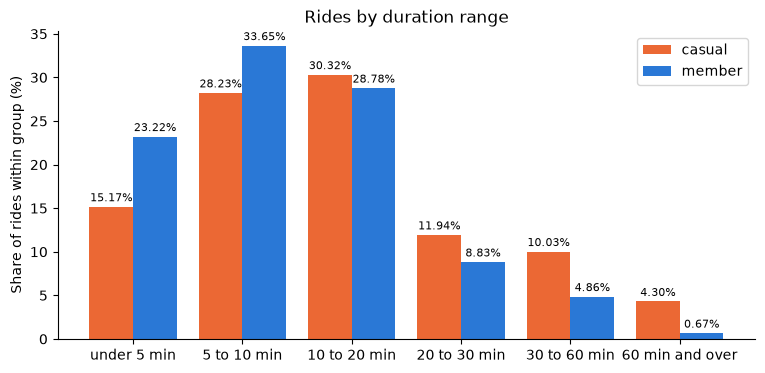

In [4]:
q2_buckets = con.sql("""
    SELECT *
    FROM q2_duration_buckets
    ORDER BY member_casual, bucket_order
""").df()
# One row per duration range, one column per group
buckets = q2_buckets.pivot(index=['bucket_order', 'duration_bucket'],
                           columns='member_casual', values='share_within_group').reset_index()
x = np.arange(len(buckets))
width = 0.4

fig, ax = plt.subplots(figsize=(9, 4))
for i, group in enumerate(['casual', 'member']):
    bars = ax.bar(x + (i - 0.5) * width, buckets[group], width, label=group, color=COLORS[group])
    ax.bar_label(bars, labels=[f'{v:.2f}%' for v in buckets[group]], padding=2, fontsize=8)

ax.set_xticks(x, buckets['duration_bucket'])
ax.set_ylabel('Share of rides within group (%)')
ax.set_title('Rides by duration range')
ax.legend()

save_fig(fig, 'q2_duration_buckets')

## Q3 When do they start riding?

Metric: the share of each group's rides that start in each hour of the day (0 to 23).

member_casual,casual,member
start_hour,,
0,2.05,0.92
1,1.34,0.56
2,0.85,0.33
3,0.49,0.21
4,0.39,0.25
5,0.62,0.97
6,1.35,2.85
7,2.47,5.64
8,3.56,7.30


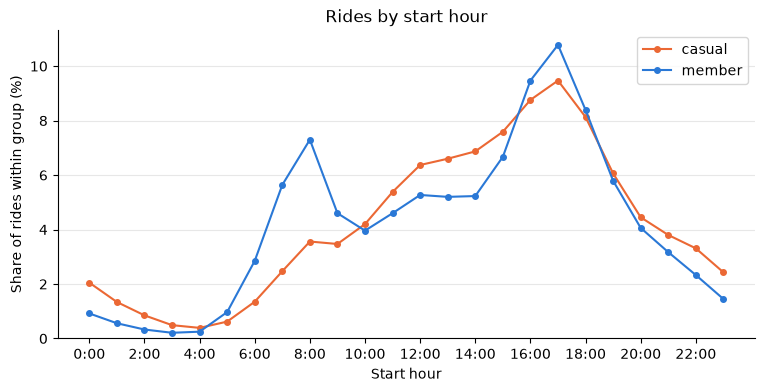

In [5]:
q3 = con.sql("""
    SELECT member_casual, start_hour, n_rides, share_within_group
    FROM q3_rides_by_hour
    ORDER BY member_casual, start_hour
""").df()

fig, ax = plt.subplots(figsize=(9, 4))
for group, rows in q3.groupby('member_casual'):
    ax.plot(rows['start_hour'], rows['share_within_group'], marker='o', markersize=4,
            color=COLORS[group], label=group)

ax.set_xticks(range(0, 24, 2), [f'{h}:00' for h in range(0, 24, 2)])
ax.set_ylim(bottom=0)
ax.set_xlabel('Start hour')
ax.set_ylabel('Share of rides within group (%)')
ax.set_title('Rides by start hour')
ax.grid(axis='y', alpha=0.3)
ax.legend()

save_fig(fig, 'q3_rides_by_hour')

# Hours as rows, one column per group, for reading the exact numbers
q3.pivot(index='start_hour', columns='member_casual', values='share_within_group')

## Q4 Which bike type do they choose?

Metric: the share of classic and electric bike rides within each group.

,member_casual,rideable_type,n_rides,share_within_group
0,casual,classic_bike,607782,29.38
1,casual,electric_bike,1460910,70.62
2,member,classic_bike,1277812,33.60
3,member,electric_bike,2524886,66.40


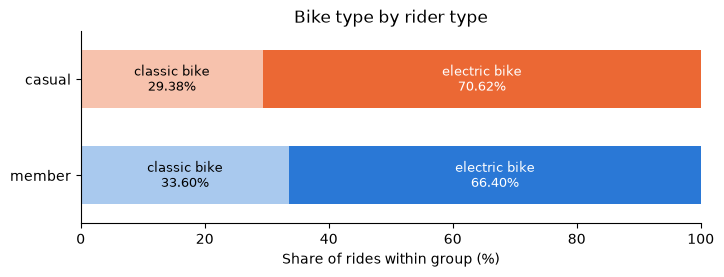

In [6]:
q4 = con.sql("""
    SELECT member_casual, rideable_type, n_rides, share_within_group
    FROM q4_bike_type
    ORDER BY member_casual, rideable_type
""").df()

# One row per group, one column per bike type
shares = q4.pivot(index='member_casual', columns='rideable_type', values='share_within_group')

fig, ax = plt.subplots(figsize=(8, 2.5))
for y, (group, row) in enumerate(shares.iterrows()):
    left = 0
    # Light shade for classic bikes, full color for electric bikes
    for bike_type, alpha in [('classic_bike', 0.4), ('electric_bike', 1.0)]:
        share = row[bike_type]
        ax.barh(y, share, left=left, color=COLORS[group], alpha=alpha, height=0.6)
        ax.text(left + share / 2, y, f"{bike_type.replace('_', ' ')}\n{share:.2f}%",
                ha='center', va='center', fontsize=9,
                color='white' if alpha == 1.0 else 'black')
        left += share

ax.set_yticks(range(len(shares)), shares.index)
ax.set_ylim(len(shares) - 0.5, -0.5)   # reversed, so casual is on top
ax.set_xlim(0, 100)
ax.set_xlabel('Share of rides within group (%)')
ax.set_title('Bike type by rider type')

save_fig(fig, 'q4_bike_type')
q4

In [7]:
con.close()